In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

# Toy problem

In [2]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
F = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect")
noisy_signal = F.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

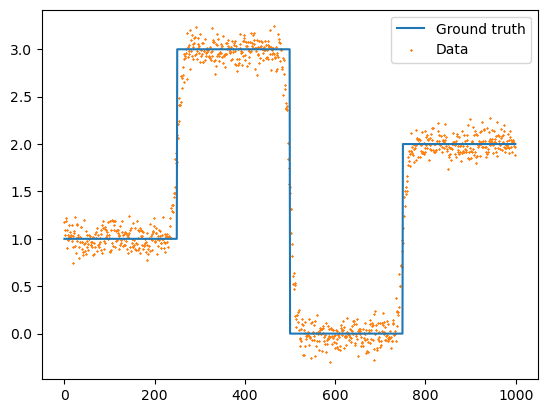

In [3]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization matrix

In [4]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

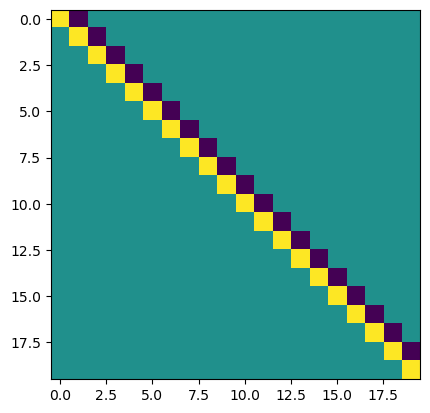

In [5]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# Solve problem with GKS-IAS

First, we will solve the problem with GKS-IAS. Then, we will use the selected $\vartheta$ parameter when we solve the problem with IAS / P-IAS (priorconditioned IAS). When we compare GKS-IAS with IAS/P-IAS, keep in mind that the later take $\vartheta$ as an input.

In [6]:
from gksias import GKSIAS

In [7]:
# Define hyperprior paramaeters
hyperpr_r = -1.0
hyperpr_beta = 1.0

# Whiten the forward operator and observation by the noise covariance (don't actually need to do this when using gcv)
Atilde = (1.0/noise_stdev)*F
btilde = (1.0/noise_stdev)*noisy_signal

# Solve problem with GKSIAS
gks_sol, gks_data = GKSIAS(Atilde, btilde, L, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
                           projection_dim=3, n_iter=200, regparam="gcv", x_true=ground_truth)
#variant="modified", fullsize=btilde.size

running MMGKS...:   0%|          | 0/200 [00:00<?, ?it/s]

running MMGKS...:  21%|██        | 42/200 [00:03<00:11, 13.65it/s] 


KeyboardInterrupt: 

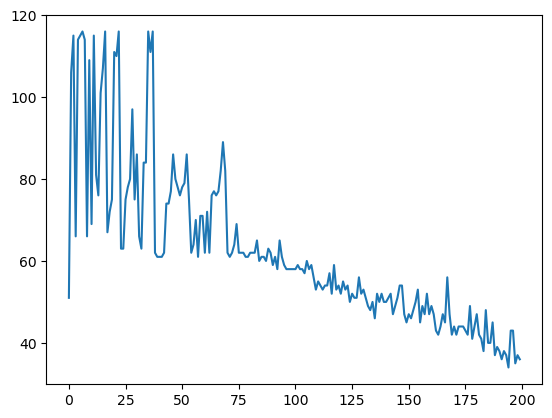

In [8]:
plt.plot(gks_data["n_gcv_evals"])
plt.show()

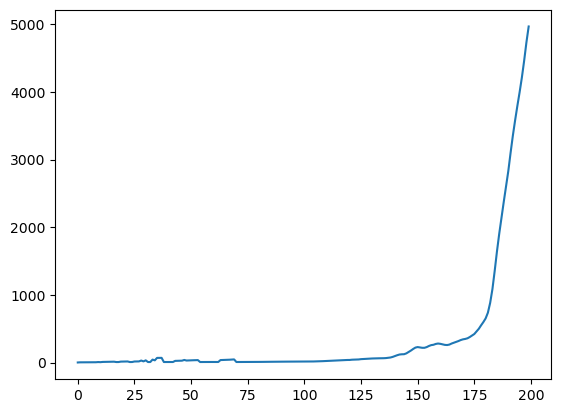

In [8]:
plt.plot(gks_data["cond_ests"])
plt.show()

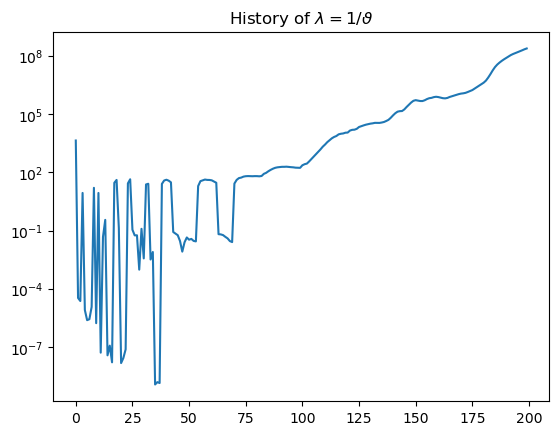

In [9]:
plt.plot(gks_data["regParam_history"])
plt.title("History of $\\lambda = 1/\\vartheta$")
plt.yscale("log")
plt.show()

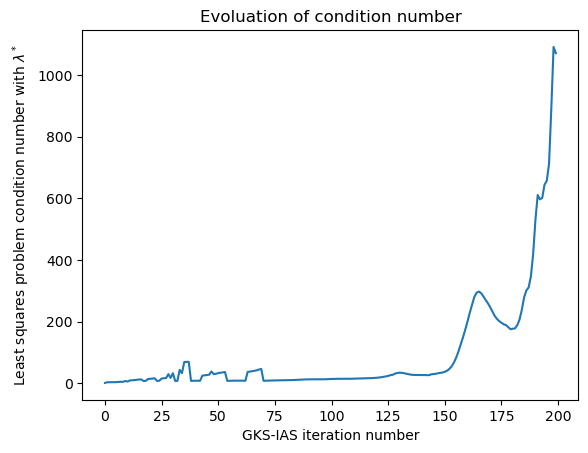

In [14]:
plt.plot(gks_data["cond_ests"])
plt.ylabel("Least squares problem condition number with $\\lambda^*$")
plt.xlabel("GKS-IAS iteration number")
plt.title("Evoluation of condition number")
plt.show()

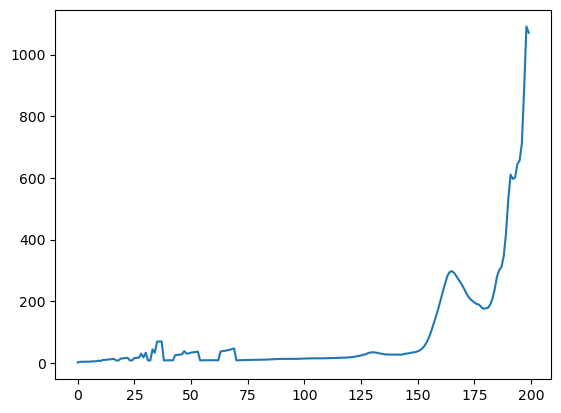

In [29]:
plt.plot(gks_data["cond_ests"])
plt.show()

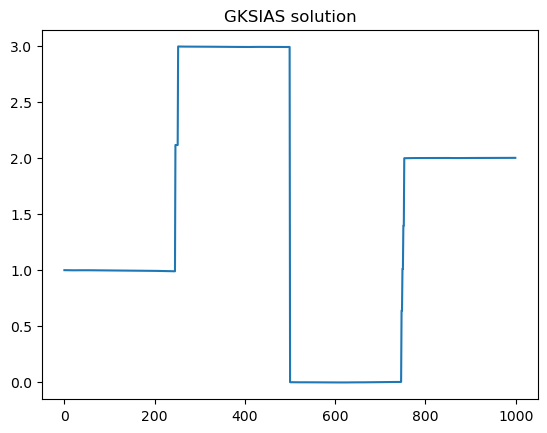

In [10]:
plt.plot( gks_sol )
plt.title("GKSIAS solution")
plt.show()

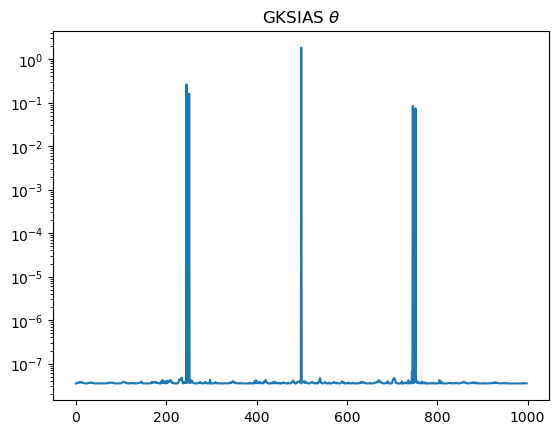

In [15]:
plt.plot(gks_data["theta"])
plt.title("GKSIAS $\\theta$")
plt.yscale("log")
plt.show()

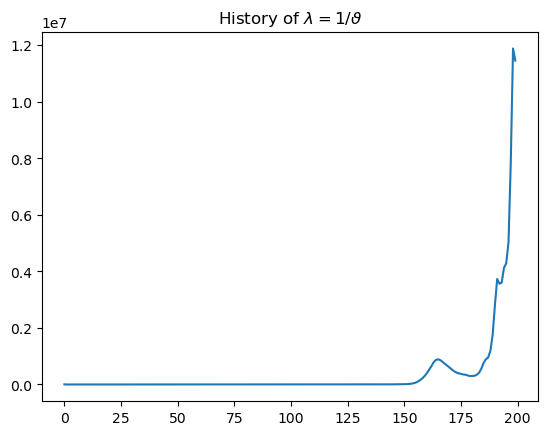

In [12]:
plt.plot(gks_data["regParam_history"])
plt.title("History of $\\lambda = 1/\\vartheta$")
plt.show()

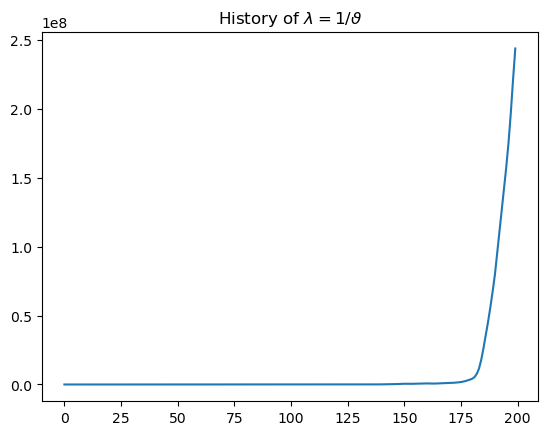

In [11]:
plt.plot(gks_data["regParam_history"])
plt.title("History of $\\lambda = 1/\\vartheta$")
plt.show()

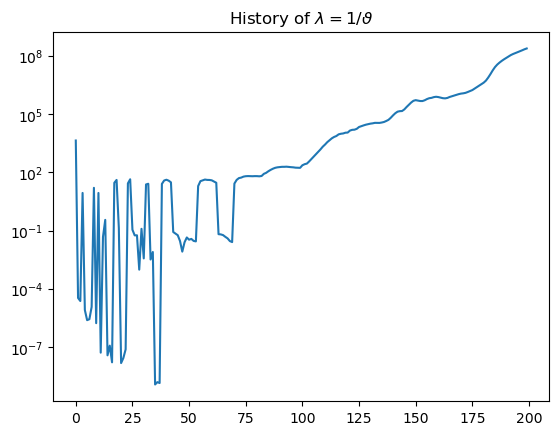

In [12]:
plt.plot(gks_data["regParam_history"])
plt.title("History of $\\lambda = 1/\\vartheta$")
plt.yscale("log")
plt.show()

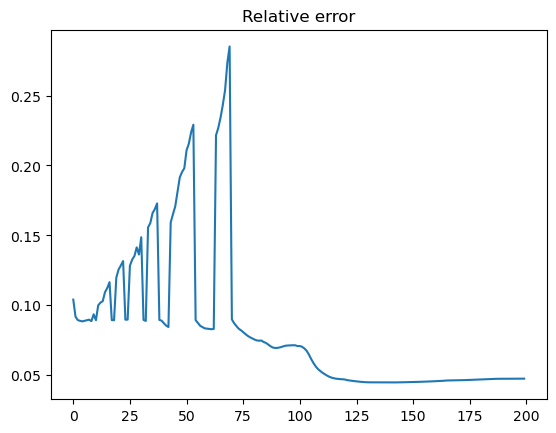

In [13]:
plt.plot(gks_data["relError"])
plt.title("Relative error")
plt.show()

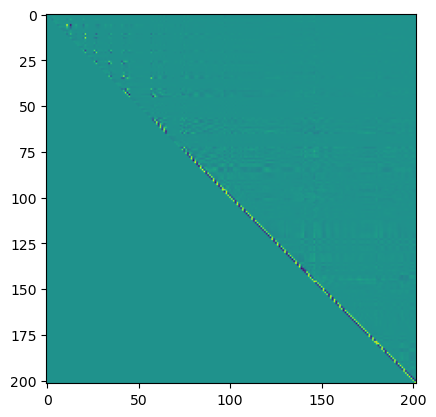

In [35]:
plt.imshow(gks_data["R_L"])
plt.show()

In [24]:
gks_data["R_L"].shape

(202, 202)

In [25]:
np.linalg.matrix_rank(gks_data["R_L"])

202

In [26]:
np.linalg.cond(gks_data["R_L"])

52540.92270155275

In [36]:
np.linalg.cond(gks_data["R_L"])

52540.92270155275

### Set up IAS and IAS with priorconditioning

In [7]:
from ias import IASSolver
import scipy.sparse as sps

In [8]:
Wtilde = Wmat / np.linalg.norm(Wmat)
Wotilde = jlinops.MatrixLinearOperator(Wtilde)

In [9]:
# Prior parameters
hyperparams = {
    "prior": {
        "r": hyperpr_r,
        "beta": hyperpr_beta,
        "vartheta": gks_data["vartheta_history"][-1], # use vartheta from GKS
    },
}

# Set up priorconditioning pseudoinverse factory (shortcut here since linearly indpendent rows, less of a cheating way below)
# _Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
# Lpinv_factory = lambda theta: _Lpinv @ jlinops.DiagonalOperator(np.sqrt(theta))

def Lpinv_factory(theta):
    Ltilde = jlinops.MatrixLinearOperator( sps.diags( 1.0/np.sqrt(theta) ) @ Lmat)
    #return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-3)
    return (jlinops.IdentityOperator((Wotilde.shape[0], Wotilde.shape[0])) - (Wotilde @ Wotilde.T) ) @ jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-3)

pdata = {
    "W": jlinops.MatrixLinearOperator(Wmat),
    "Rpinv_factory": Lpinv_factory,
}

# Create solver
ias_solver = IASSolver(F, L, noisy_signal, hyperparams, noise_var=noise_var, pdata={})
pias_solver = IASSolver(F, L, noisy_signal, hyperparams, noise_var=noise_var, pdata=pdata)

NameError: name 'hyperpr_r' is not defined

In [69]:
ias_data = ias_solver.solve(max_iters=200, eps=1e-8, x_update_solver_params={"tol":1e-7}, x_true=ground_truth)
pias_data = pias_solver.solve(max_iters=200, eps=1e-8, x_update_solver_params={"tol":1e-6}, x_true=ground_truth, priorconditioning=True)

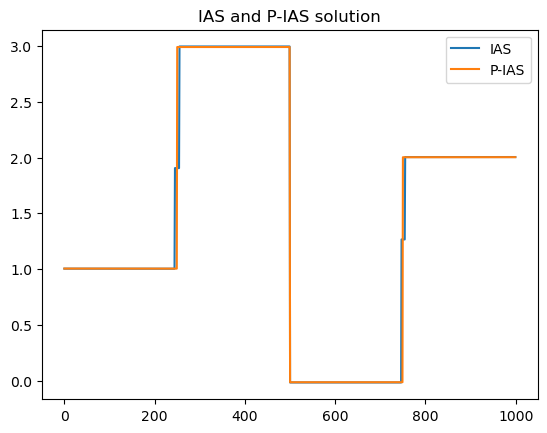

In [70]:
plt.plot(ias_data["x"], label="IAS")
plt.plot(pias_data["x"], label="P-IAS")
plt.title("IAS and P-IAS solution")
plt.legend()
plt.show()

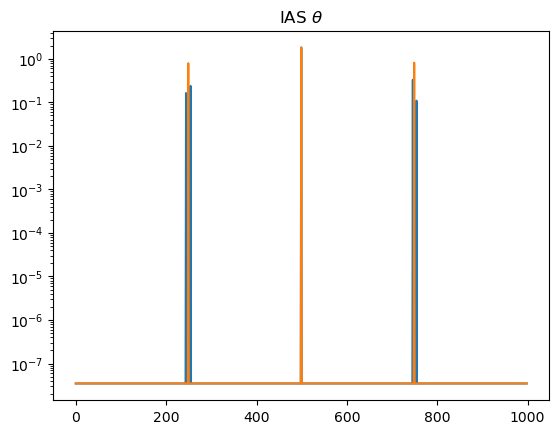

In [71]:
plt.plot(ias_data["theta"])
plt.plot(pias_data["theta"])
plt.title("IAS $\\theta$")
plt.yscale("log")
plt.show()

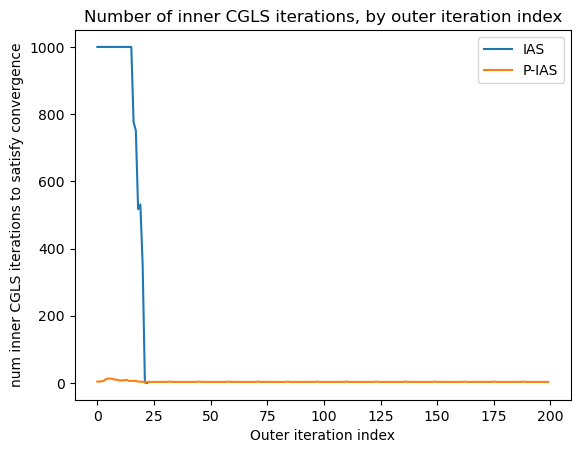

In [72]:
plt.plot(ias_data["n_cg_its_per_iteration"], label="IAS")
plt.plot(pias_data["n_cg_its_per_iteration"], label="P-IAS")
plt.title("Number of inner CGLS iterations, by outer iteration index")
plt.xlabel("Outer iteration index")
plt.ylabel("num inner CGLS iterations to satisfy convergence")
plt.legend()
plt.show()

In [55]:
print(np.cumsum(ias_data["n_cg_its_per_iteration"]))
print(np.cumsum(pias_data["n_cg_its_per_iteration"]))

[ 1000  2000  3000  4000  5000  6000  7000  8000  9000 10000 11000 12000
 13000 14000 15000 16000 16776 17527 18044 18575 18928 18929 18929]
[  4   8  13  20  31  45  57  68  78  88  95 103 111 120 126 132 138 144
 148 152 155 158]


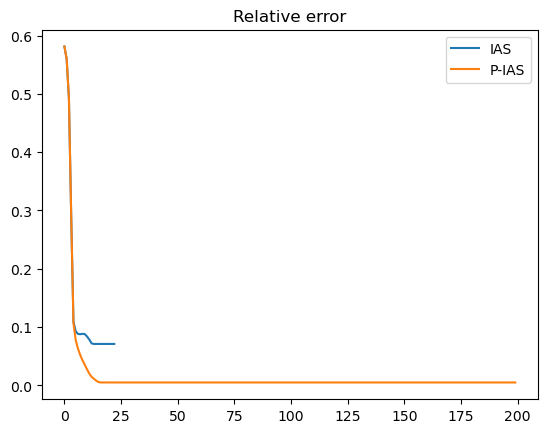

In [73]:
plt.plot(ias_data["rel_errs"], label="IAS")
plt.plot(pias_data["rel_errs"], label="P-IAS")
plt.title("Relative error")
plt.legend()
plt.show()

# Comparison 

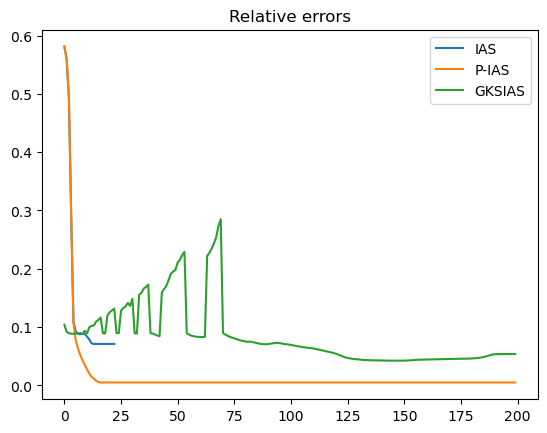

In [74]:
plt.plot(ias_data["rel_errs"], label="IAS")
plt.plot(pias_data["rel_errs"], label="P-IAS")
plt.plot(gks_data["relError"], label="GKSIAS")
plt.legend()
plt.title("Relative errors")
plt.show()

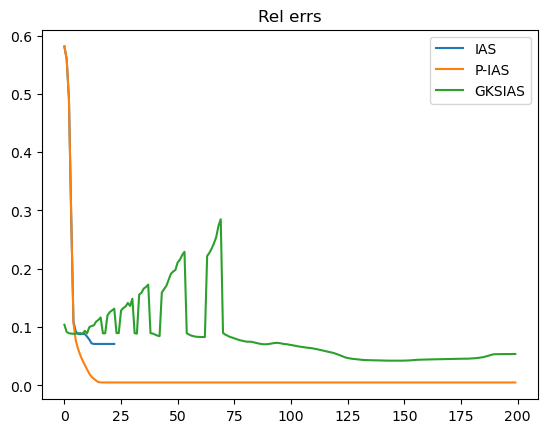

In [75]:
plt.plot(ias_data["rel_errs"], label="IAS")
plt.plot(pias_data["rel_errs"], label="P-IAS")
plt.plot(gks_data["relError"], label="GKSIAS")
plt.legend()
plt.title("Rel errs")
plt.show()

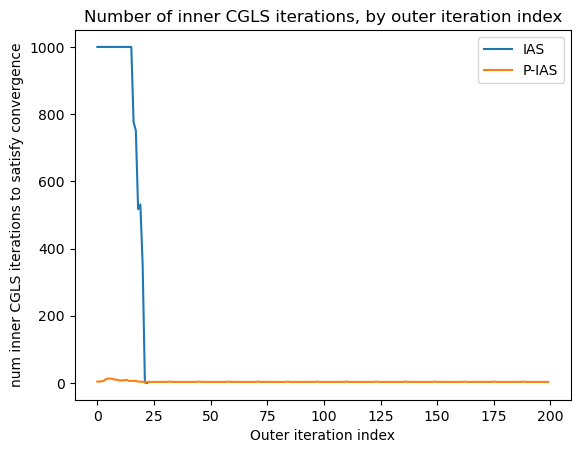

In [76]:
plt.plot(ias_data["n_cg_its_per_iteration"], label="IAS")
plt.plot(pias_data["n_cg_its_per_iteration"], label="P-IAS")
plt.title("Number of inner CGLS iterations, by outer iteration index")
plt.xlabel("Outer iteration index")
plt.ylabel("num inner CGLS iterations to satisfy convergence")
plt.legend()
plt.show()

### What if we don't pick lambda by GCV, and instead fix it to the same lambda implied by above? How many iterations do we need to get a good reconstruction?

In [77]:
# Define hyperprior paramaeters
hyperpr_r = -1.0
hyperpr_beta = 1.0

# Whiten the forward operator and observation by the noise covariance (don't actually need to do this when using gcv)
Atilde = (1.0/noise_stdev)*F
btilde = (1.0/noise_stdev)*noisy_signal

# Solve problem with GKSIAS
gks_sol2, gks_data2 = GKSIAS(Atilde, btilde, L, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
                           projection_dim=3, n_iter=200, regparam="gcv", x_true=ground_truth, regparam_fixed=1.0/gks_data["vartheta_history"][-1])

running MMGKS...: 100%|██████████| 200/200 [00:10<00:00, 19.47it/s]


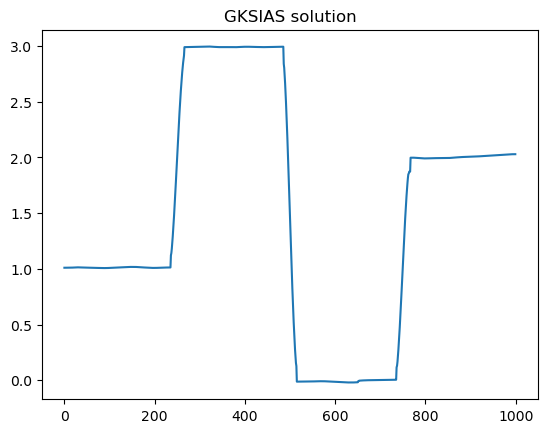

In [78]:
plt.plot( gks_sol2 )
plt.title("GKSIAS solution")
plt.show()

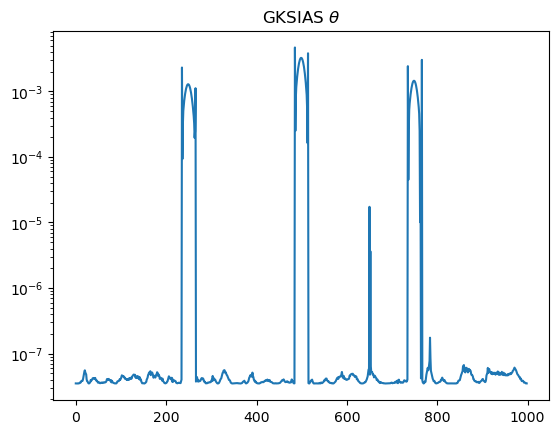

In [79]:
plt.plot(gks_data2["theta"])
plt.title("GKSIAS $\\theta$")
plt.yscale("log")
plt.show()

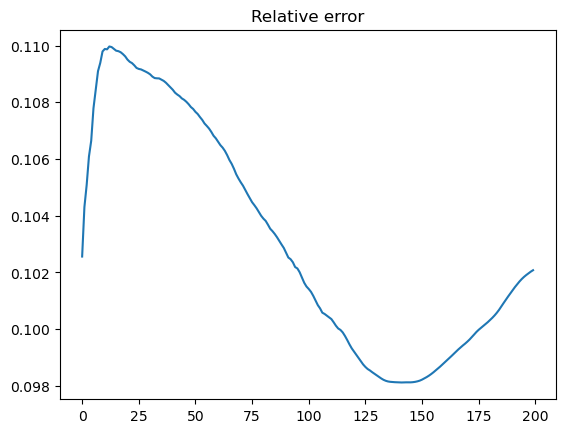

In [80]:
plt.plot(gks_data2["relError"])
plt.title("Relative error")
plt.show()

# PGKSIAS?

In [8]:
from pgksias import PGKSIAS
import scipy.sparse as sps

In [9]:
# Set up priorconditioning pseudoinverse factory (shortcut here since linearly indpendent rows, less of a cheating way below)
# _Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
# Lpinv_factory = lambda wr: _Lpinv @ jlinops.DiagonalOperator(1.0/wr)

def Lpinv_factory(wr):
    Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
    return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

W = jlinops.MatrixLinearOperator(Wmat)

# Define hyperprior paramaeters
hyperpr_r = -1.0
hyperpr_beta = 1.0

# Whiten the forward operator and observation by the noise covariance (don't actually need to do this when using gcv)
Atilde = (1.0/noise_stdev)*F
btilde = (1.0/noise_stdev)*noisy_signal

# Solve problem with GKSIAS
gks_sol3, gks_data3 = PGKSIAS(Atilde, btilde, L, W=W, Lpinv_factory=Lpinv_factory, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
                           projection_dim=3, n_iter=200, regparam="gcv", x_true=ground_truth, 
                           #regparam_fixed=1.0/gks_data["vartheta_history"][-1]
                           )
#variant="modified", fullsize=btilde.size

running MMGKS...: 100%|██████████| 200/200 [09:41<00:00,  2.91s/it]


In [10]:
plt.plot( gks_sol, label="No priorconditioning" )
plt.plot( gks_sol3, label="With priorconditioning" )
plt.title("GKSIAS solution")
plt.show()

NameError: name 'gks_sol' is not defined

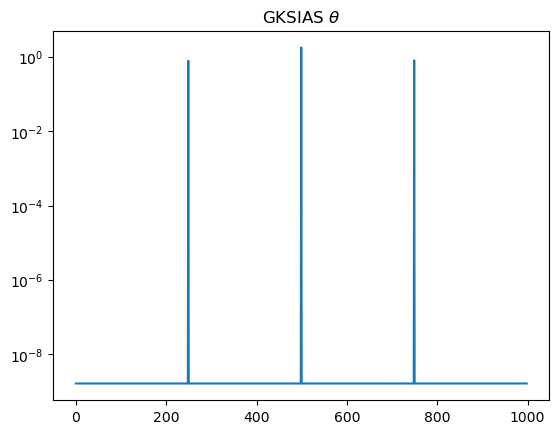

In [ ]:
plt.plot(gks_data3["theta"])
plt.title("GKSIAS $\\theta$")
plt.yscale("log")
plt.show()

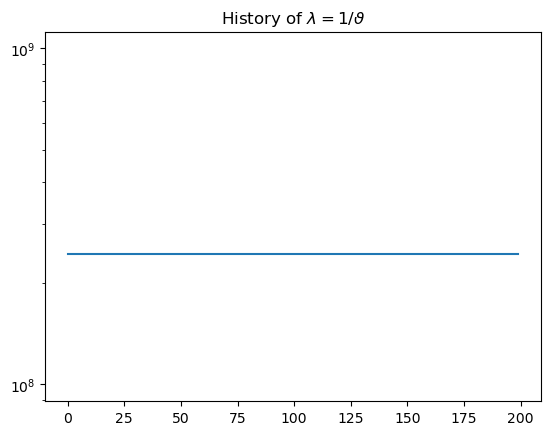

In [ ]:
plt.plot(gks_data3["regParam_history"])
plt.title("History of $\\lambda = 1/\\vartheta$")
plt.yscale("log")
plt.show()

# Compare both

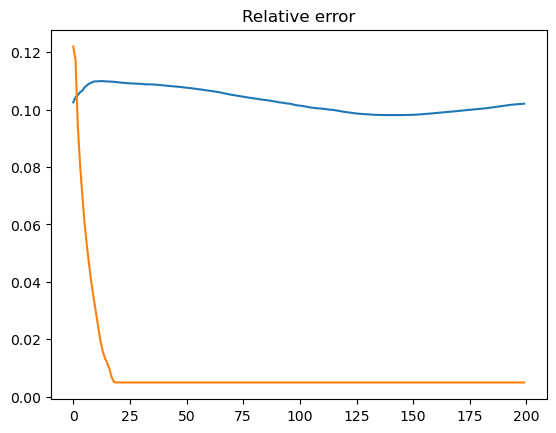

In [43]:
plt.plot(gks_data2["relError"], label="No preconditioning")
plt.plot(gks_data3["relError"], label="With preconditioning")
plt.title("Relative error")
plt.show()

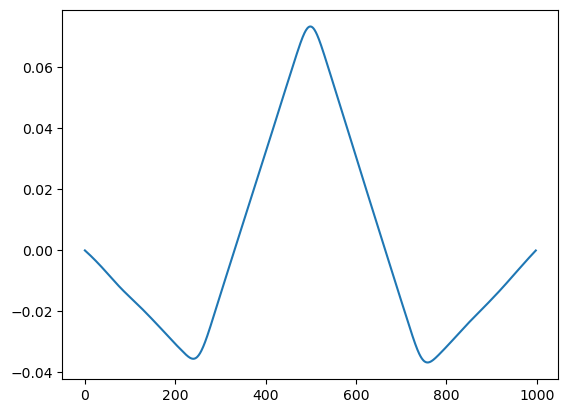

In [44]:
plt.plot(gks_data["V"][:,0])
plt.show()

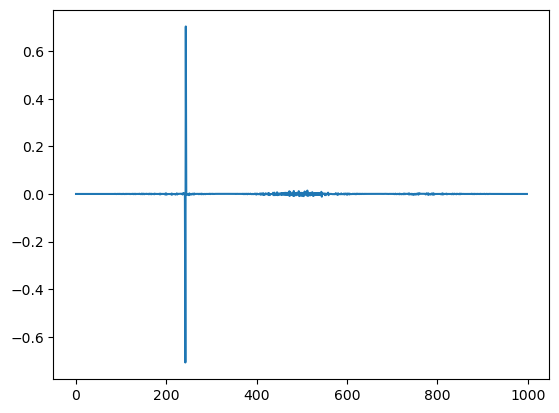

In [38]:
plt.plot(gks_data["V"][:,10])
plt.show()